# Práctica de explicabilidad - Reservas de hotel

Lucía Martínez Miramontes

## 0.1. Entorno (Notebook Autoejecutable)

In [1]:
%pip install -q numpy pandas scikit-learn imbalanced-learn statsmodels shap matplotlib


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import imblearn
import shap
import statsmodels.api as sm
from IPython.display import display

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SequentialFeatureSelector, mutual_info_classif
from sklearn.metrics import (confusion_matrix, f1_score, precision_score, recall_score,
                             roc_auc_score, average_precision_score, make_scorer)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)
os.makedirs("figuras", exist_ok=True)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 0.2. Datos y preparación

El preprocesamiento se realiza de la misma manera que en la práctcia anterior. Se realiza un EDA inicial para observar la distribución y limpieza de los datos. La partición será igual y también estratificada. Misma validación cruzada (`StratifiedKFold` de 5 particiones sobre el entrenamiento), misma métrica principal (F1 de la clase positiva) y mismo tratamiento del desequilibrio (sobremuestreo aleatorio dentro del `Pipeline`), ya que este resulto ser el que devolvía un mejor rendimiento en la clasificación. El test solo se usa al final de cada apartado.

In [3]:
d = pd.read_csv("01_reservas_hotel.csv")
print(f"Filas: {d.shape[0]}  |  Columnas: {d.shape[1]}")
display(d.head())

Filas: 6000  |  Columnas: 12


,id_reserva,antelacion_dias,noches,huespedes,precio_noche_eur,reservas_previas,ausencias_previas,cambios_reserva,solicitudes_especiales,deposito_pagado,llegada_fin_semana,no_presentado
0,R00000,9,5,2,133.57,2,0,1,0,1,1,0
1,R00001,8,4,3,61.00,0,0,0,0,0,1,0
2,R00002,20,2,2,74.78,3,0,1,1,1,1,0
3,R00003,23,4,3,106.67,2,0,3,0,1,0,0
4,R00004,27,2,1,131.65,3,0,0,0,1,1,0


Se eliminan los identificadores (en este caso el id_reserva) y el atributo objetivo que es el booleano "no_presentado".

In [4]:
# Roles: id_reserva (identificador) y no_presentado (objetivo) no entran en X
X = d.drop(columns=["id_reserva", "no_presentado"])
y = d["no_presentado"]
print(f"Predictores: {X.shape[1]}")
print("\nTipos de datos:")
print(d.dtypes)

Predictores: 10

Tipos de datos:
id_reserva                    str
antelacion_dias             int64
noches                      int64
huespedes                   int64
precio_noche_eur          float64
reservas_previas            int64
ausencias_previas           int64
cambios_reserva             int64
solicitudes_especiales      int64
deposito_pagado             int64
llegada_fin_semana          int64
no_presentado               int64
dtype: object


Quedan 10 predictores, estos describen la reserva o el historial del cliente y se conocen antes de la llegada, así que entran todos. Asumimos que "cambios_reserva" es válido por que cuenta los cambios hechos hasta el momento de la llamada y no incluye cambios posteriores (por ejemplo, una cancelación de última hora registrada como cambio). Se da por bueno, igual que en la primera práctica.

In [5]:
# Tipos de variable (los mismos de la primera práctica)
BINARIAS = ["ausencias_previas", "deposito_pagado", "llegada_fin_semana"]
DISCRETAS = ["noches", "huespedes", "reservas_previas", "cambios_reserva", "solicitudes_especiales"]
CONTINUAS = ["antelacion_dias", "precio_noche_eur"]
assert set(BINARIAS + DISCRETAS + CONTINUAS) == set(X.columns)

# Partición entrenamiento / test y validación cruzada, idénticas a la primera práctica
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print(f"Entrenamiento: {len(X_train)} reservas ({y_train.mean():.1%} no presentados)")
print(f"Test:          {len(X_test)} reservas ({y_test.mean():.1%} no presentados)")

Entrenamiento: 4500 reservas (8.0% no presentados)
Test:          1500 reservas (8.0% no presentados)


Obtenemos 4500 reservas en entrenamiento (y validación de la validación cruzada) y 1500 de test. Vemos que hay un 8% de la clase positiva en ambos conjuntos debido a la estratificación.

**Métricas, coste y umbral.** La F1 de la clase positiva decide en validación cruzada (umbral 0,5). Se registrará también precision, recall, ROC-AUC y AP (*average precision*), que no dependen del umbral. Igual que en la primera práctica, el umbral de trabajo se elige en validación con el coste ilustrativo del enunciado (70 € por falso negativo y 3 € por falso positivo) entre 0,3, 0,5 y 0,7.

In [6]:
scoring = {
    "f1":        make_scorer(f1_score, zero_division=0),
    "precision": make_scorer(precision_score, zero_division=0),
    "recall":    make_scorer(recall_score),
    "roc_auc":   "roc_auc",
    "AP":        "average_precision",
}
resultados = {}   # nombre -> {métrica: (media, desviación)} en validación cruzada

def evaluar_cv(nombre, modelo, X_=None):
    """Evalúa el Pipeline completo con el cv común y guarda media y desviación típica de cada métrica."""
    X_ = X_train if X_ is None else X_
    r = cross_validate(modelo, X_, y_train, cv=cv, scoring=scoring, error_score="raise")
    resultados[nombre] = {m: (r[f"test_{m}"].mean(), r[f"test_{m}"].std()) for m in scoring}
    return resultados[nombre]

def tabla_resultados():
    return pd.DataFrame({n: {m: f"{mu:.3f} ± {sd:.3f}" for m, (mu, sd) in r.items()}
                         for n, r in resultados.items()}).T

COSTE_FN, COSTE_FP = 70, 3
UMBRALES = [0.3, 0.5, 0.7]

def coste_por_1000(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    return (COSTE_FN * fn + COSTE_FP * fp) / len(y_true) * 1000

def metricas_umbral(y_true, y_prob, t):
    pred = (y_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"umbral": t, "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred), "F1": f1_score(y_true, pred, zero_division=0),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "coste por 1.000 reservas (€)": coste_por_1000(y_true, pred)}

def elegir_umbral(y_prob_val):
    """Umbral de menor coste en VALIDACIÓN (probabilidades de validación cruzada del entrenamiento)."""
    t = pd.DataFrame([metricas_umbral(y_train, y_prob_val, u) for u in UMBRALES]).set_index("umbral")
    return float(t["coste por 1.000 reservas (€)"].idxmin()), t

def metricas_test(y_prob, t):
    fila = metricas_umbral(y_test, y_prob, t)
    fila.update({"ROC-AUC": roc_auc_score(y_test, y_prob), "AP": average_precision_score(y_test, y_prob)})
    return fila

**Modelo de partida.** El modelo que se obtuvo como "mejor" en la primera práctica es el siguiente: escalado, sobremuestreo aleatorio de la clase positiva y regresión logística, todo en un Pipeline de imblearn para que el escalado y el remuestreo se ajusten solo con el entrenamiento de cada partición. Lo usamos como estimador dentro de la selección de variables y como referencia con las 10 variables. Es un modelo interpretable por lo que se usará para el ejercicio dos de la práctica. 

In [7]:
def regresion_logistica_ros():
    return ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", RandomOverSampler(random_state=SEED)),
        ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
    ])

evaluar_cv("LR + sobremuestreo · 10 variables (práctica 1)", regresion_logistica_ros())
tabla_resultados()

,f1,precision,recall,roc_auc,AP
LR + sobremuestreo · 10 variables (práctica 1),0.254 ± 0.016,0.157 ± 0.011,0.672 ± 0.052,0.740 ± 0.018,0.245 ± 0.044


## 1. Selección de variables: FFS

Para la seleccion de variables se aplica un método wrapper, FFS (*Forward Feature Selection*) que es la selección hacia delante: se empieza sin variables y en cada paso se añade la que más mejora la F1 media en validación cruzada del modelo completo (escalado + sobremuestreo + regresión logística). A diferencia de un filtro, evalúa las variables juntas y con el modelo que se va a usar, así que tiene en cuenta la redundancia entre ellas y su efecto sobre el modelo concreto.

Como una comparativa adicional, se aplica también un filtros univariantes, que ordena las variables una a una sin entrenar el modelo.

### 1.1 Referencia: filtro univariante

Dos criterios sobre el entrenamiento: la correlación con la clase (punto-biserial, solo capta relaciones lineales) y la información mutua (capta cualquier dependencia, también no lineal).

In [8]:
corr = X_train.assign(no_presentado=y_train).corr()["no_presentado"].drop("no_presentado")
mi = pd.Series(
    mutual_info_classif(X_train, y_train, discrete_features=[X.columns.get_loc(c) for c in BINARIAS + DISCRETAS],
                        random_state=SEED),
    index=X.columns,
)
filtro = pd.DataFrame({"correlación": corr, "|correlación|": corr.abs(), "información mutua": mi})
filtro["puesto |corr|"] = filtro["|correlación|"].rank(ascending=False).astype(int)
filtro["puesto IM"] = filtro["información mutua"].rank(ascending=False).astype(int)
display(filtro.sort_values("|correlación|", ascending=False).round(4))

,correlación,|correlación|,información mutua,puesto |corr|,puesto IM
cambios_reserva,0.1648,0.1648,0.0118,1,2
reservas_previas,-0.1585,0.1585,0.0167,2,1
deposito_pagado,-0.1380,0.1380,0.0091,3,3
ausencias_previas,0.0941,0.0941,0.0034,4,6
antelacion_dias,0.0829,0.0829,0.0068,5,4
solicitudes_especiales,-0.0802,0.0802,0.0040,6,5
noches,0.0210,0.0210,0.0015,7,7
precio_noche_eur,0.0048,0.0048,0.0000,8,10
huespedes,0.0038,0.0038,0.0000,9,8
llegada_fin_semana,0.0001,0.0001,0.0000,10,9


Los dos criterios solo coinciden en que el deposito_pagado es la variable en tercer puesto y noches el séptimo en cuanto a su relación con la clase, sin embargo el orden general coincide en lo esencial con solo pequeñas diferencias. 

Por lo general las correlaciones no son nada fuertes, vemos que llegada_fin_semana es prácticamente independiente de la clase. No obstante, los índices bajos pueden deberse a que las variables aportan conjuntamente pero también a que hay un desequilibrio importante de las clases binarias por lo que es dificil hayar patrones significativos con la clase positiva.

El filtro es rápido, pero mira cada variable por separado: no sabe si dos variables cuentan lo mismo ni cuánto aporta cada una al modelo que se va a usar. Para eso está el *wrapper*.

### 1.2 Selección hacia delante paso a paso (FFS)

Se aplica de 1 a 10 variables para ver cómo evoluciona la F1 al añadirlas. En cada paso se prueban todas las variables que quedan con el mismo cv y se queda la de mayor F1 media. Anotamos también ROC-AUC y AP, que no deciden pero ayudan a interpretar.

In [9]:
def camino_ffs(X_, y_, modelo_fn):
    elegidas, restantes, filas = [], list(X_.columns), []
    while restantes:
        puntuaciones = {}
        for c in restantes:
            r = cross_validate(modelo_fn(), X_[elegidas + [c]], y_, cv=cv, scoring=scoring)
            puntuaciones[c] = {m: (r[f"test_{m}"].mean(), r[f"test_{m}"].std()) for m in scoring}
        mejor = max(puntuaciones, key=lambda c: puntuaciones[c]["f1"][0])
        elegidas.append(mejor)
        restantes.remove(mejor)
        p = puntuaciones[mejor]
        filas.append({"n.º variables": len(elegidas), "variable añadida": mejor,
                      "F1": p["f1"][0], "F1 desv.": p["f1"][1],
                      "ROC-AUC": p["roc_auc"][0], "AP": p["AP"][0]})
    return pd.DataFrame(filas).set_index("n.º variables")

camino = camino_ffs(X_train, y_train, regresion_logistica_ros)
display(camino.round(3))

,variable añadida,F1,F1 desv.,ROC-AUC,AP
n.º variables,,,,,
1,deposito_pagado,0.212,0.011,0.623,0.109
2,reservas_previas,0.233,0.010,0.713,0.152
3,cambios_reserva,0.247,0.010,0.734,0.217
4,ausencias_previas,0.257,0.015,0.742,0.230
5,huespedes,0.256,0.015,0.740,0.234
6,solicitudes_especiales,0.256,0.015,0.742,0.237
7,llegada_fin_semana,0.255,0.015,0.741,0.238
8,precio_noche_eur,0.253,0.017,0.740,0.238
9,antelacion_dias,0.253,0.016,0.741,0.245


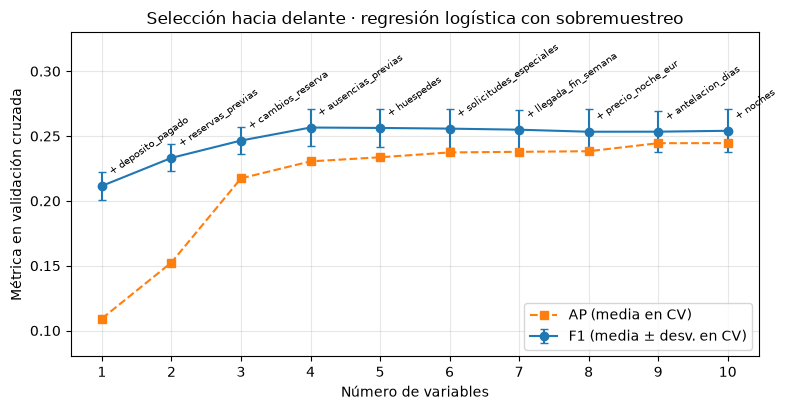

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.errorbar(camino.index, camino["F1"], yerr=camino["F1 desv."], marker="o", capsize=3, label="F1 (media ± desv. en CV)")
ax.plot(camino.index, camino["AP"], marker="s", ls="--", label="AP (media en CV)")
for k, fila in camino.iterrows():
    ax.annotate(f"+ {fila['variable añadida']}", (k, fila["F1"]), textcoords="offset points", xytext=(4, 8),
                fontsize=7, rotation=35)
ax.set(xlabel="Número de variables", ylabel="Métrica en validación cruzada", xticks=camino.index,
       title="Selección hacia delante · regresión logística con sobremuestreo")
ax.set_ylim(0.08, 0.33)
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig("figuras/ffs_camino.png", dpi=200, bbox_inches="tight")
plt.show()

En cuanto al orden de las variables, podemos ver algunas diferencias importantes respecto a los filtros univariantes. Por ejemplo, mientras que las primeras 4 son justo las encontradas por la correlacion de Pearson y las primeras tres por la información mutua, huespedes esta de quinta mientras que los filtros la ponían como novena y octava, lo mismo ocurre con llegada_fin_semana.

Es interesante ver que una variable que parece no tener correlación con la variable objetivo en un principio resulte luego mejorar el modelo más que otras, sin embargo en el algoritmo FFS se tiene en cuenta no solo el orden si no cuando una variable deja de mejorar el modelo.

**Criterio de parada.** Paramos cuando añadir otra variable no mejora la F1 media en validación cruzada; es el criterio que aplica SequentialFeatureSelector de scikit-learn con n_features_to_select="auto" y una tolerancia muy pequeña. Lo comprobamos con la implementación de scikit-learn, que da el mismo conjunto:

In [11]:
ffs = SequentialFeatureSelector(regresion_logistica_ros(), direction="forward", n_features_to_select="auto",
                                tol=1e-4, scoring="f1", cv=cv)
ffs.fit(X_train, y_train)
VARIABLES_FFS = [c for c in camino["variable añadida"] if c in X.columns[ffs.get_support()]]
print(f"Variables seleccionadas por FFS ({len(VARIABLES_FFS)}): {VARIABLES_FFS}")
print(f"Descartadas: {[c for c in X.columns if c not in VARIABLES_FFS]}")
assert VARIABLES_FFS == list(camino["variable añadida"].iloc[:len(VARIABLES_FFS)]), "scikit-learn y el camino no coinciden"

Variables seleccionadas por FFS (4): ['deposito_pagado', 'reservas_previas', 'cambios_reserva', 'ausencias_previas']
Descartadas: ['antelacion_dias', 'noches', 'huespedes', 'precio_noche_eur', 'solicitudes_especiales', 'llegada_fin_semana']


Es decir, las cuatro variables elegidas son 'deposito_pagado', 'reservas_previas', 'cambios_reserva', 'ausencias_previas', por lo que huespedes que llamo la atención no entra, de hecho mirando los resultados de F1 no solo no lo mejora si no que lo empeora.

Por lo tanto, no es que FFS muestre que una variable sin correlacion con la clase positiva mejore el modelo, simplemente era la que menos lo empeoraba de las restantes, esto probablemente se deba a que, al tener a penas importancia la regresion logistica la aplica un coeficiente de 0 o muy proximo a ello, por tanto casi no afecta al resultado ya sea para bien o para mal, mientras que otras con coeficientes mayores si empeoran más pues afectan al modelo aún no encajando bien. 

### 1.3 ¿Es estable la selección? Validación cruzada anidada

La F1 del camino está calculada con las mismas particiones que se usaron para elegir las variables, así que es algo optimista. Para estimarla sin ese sesgo metemos el selector dentro del `Pipeline` y evaluamos con validación cruzada anidada: en cada partición externa el FFS se repite desde cero solo con su parte de entrenamiento (con su propio cv interno). Así vemos también si en las cinco particiones se eligen las mismas variables.

In [12]:
cv_interno = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
pipeline_ffs = Pipeline([
    ("ffs", SequentialFeatureSelector(regresion_logistica_ros(), direction="forward", n_features_to_select="auto",
                                      tol=1e-4, scoring="f1", cv=cv_interno)),
    ("modelo", regresion_logistica_ros()),
])
r_anidada = cross_validate(pipeline_ffs, X_train, y_train, cv=cv, scoring=scoring, return_estimator=True)

seleccion_por_particion = pd.DataFrame(
    [{c: ("✓" if c in X.columns[est.named_steps["ffs"].get_support()] else "") for c in X.columns}
     for est in r_anidada["estimator"]],
    index=[f"partición {i}" for i in range(1, 6)],
)
print("Variables elegidas por el FFS en cada partición externa:")
display(seleccion_por_particion)
resultados["FFS dentro del Pipeline (CV anidada)"] = {m: (r_anidada[f"test_{m}"].mean(), r_anidada[f"test_{m}"].std())
                                                     for m in scoring}
tabla_resultados()

Variables elegidas por el FFS en cada partición externa:


,antelacion_dias,noches,huespedes,precio_noche_eur,reservas_previas,ausencias_previas,cambios_reserva,solicitudes_especiales,deposito_pagado,llegada_fin_semana
partición 1,✓,,,,✓,✓,✓,,✓,
partición 2,,,,,✓,✓,✓,✓,✓,
partición 3,✓,,,✓,✓,✓,✓,,✓,
partición 4,✓,,,✓,✓,✓,✓,,✓,
partición 5,,,,✓,✓,✓,✓,,✓,


,f1,precision,recall,roc_auc,AP
LR + sobremuestreo · 10 variables (práctica 1),0.254 ± 0.016,0.157 ± 0.011,0.672 ± 0.052,0.740 ± 0.018,0.245 ± 0.044
FFS dentro del Pipeline (CV anidada),0.252 ± 0.010,0.155 ± 0.007,0.664 ± 0.034,0.746 ± 0.014,0.238 ± 0.035


Primero vemos una cosa que llama la atención, aun que sobre todo el set de entrenamiento obtuviesemos una seleccion de 4 variables, con la validacion curzada se obtienen siempre o 5 o 6.

Las cuatro variables del FFS (reservas_previas, ausencias_previas, cambios_reserva y deposito_pagado) se eligen en todas las particiones externas, así que la selección es estable. Lo que varía son los añadidos: antelacion_dias y precio_noche_eur entran en tres particiones y solicitudes_especiales en una. Son variables que mejoran la F1 media por debajo de su desviación típica (ruido), y entran porque la tolerancia es muy pequeña; con una tolerancia mayor no entrarían.

La F1 en validación anidada (0,252 ± 0,010) es muy parecida a la del camino (0,257) y a la del modelo con las 10 variables (0,254 ± 0,016). El optimismo de elegir y evaluar con las mismas particiones es pequeño, y **con cuatro variables se obtiene lo mismo que con diez**. Para el resto de la práctica nos quedamos con las cuatro elegidas sobre todo el entrenamiento.

## 2. Un modelo interpretable: regresión logística

Como modelo interpretable se elege la regresión logística porque fue el modelo seleccionado en la primera práctica (así la explicación es la del modelo que de verdad recomendamos al hotel), porque la clase es binaria y porque sus coeficientes se leen directamente como efecto de cada variable sobre el riesgo. Un árbol de decisión poco profundo habría sido la otra opción natural, pero suele ser menos estable y rendir algo peor.

Usamos la misma regresión logística con sobremuestreo, ahora solo con las variables del FFS. Es interpretable debido a su propia construcción, la predicción es una suma ponderada de las variables en la escala del log-odds,

$$\log\frac{p}{1-p} = \beta_0 + \beta_1 z_1 + \dots + \beta_k z_k ,$$

así que cada coeficiente dice cuánto y en qué sentido mueve una variable el riesgo de no presentarse, y la misma suma explica cada predicción concreta. 

La selección de columnas va dentro del `Pipeline`, de modo que el modelo recibe las 10 columnas originales y se queda con las elegidas.

In [13]:
def selector(columnas):
    return ColumnTransformer([("ffs", "passthrough", columnas)], remainder="drop",
                             verbose_feature_names_out=False).set_output(transform="pandas")

modelo_lr = ImbPipeline([
    ("seleccion", selector(VARIABLES_FFS)),
    ("scaler", StandardScaler()),
    ("sampler", RandomOverSampler(random_state=SEED)),
    ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
])
evaluar_cv(f"LR + sobremuestreo · {len(VARIABLES_FFS)} variables FFS", modelo_lr)
tabla_resultados()

,f1,precision,recall,roc_auc,AP
LR + sobremuestreo · 10 variables (práctica 1),0.254 ± 0.016,0.157 ± 0.011,0.672 ± 0.052,0.740 ± 0.018,0.245 ± 0.044
FFS dentro del Pipeline (CV anidada),0.252 ± 0.010,0.155 ± 0.007,0.664 ± 0.034,0.746 ± 0.014,0.238 ± 0.035
LR + sobremuestreo · 4 variables FFS,0.257 ± 0.015,0.158 ± 0.010,0.681 ± 0.063,0.742 ± 0.015,0.230 ± 0.035


Como observamos en la sección de selección de variables, con esas 4 obtenidas tenemos un F1 de 0.257, mayor que en la práctica 1 con todas las variables que, como hemos visto, empeoraban el rendimiento. Menos por AP mejora en todas las métricas. 

En cuanto al F1, mientras que mejora es solo un aumento de 0.003 y dadas las desviaciones típicas rondando el valor de ± 0.015, esta diferencia es ínfima por lo que tampoco sería adecuado aportarle a esta selección de variables una mejora real. Lo que sí implica es que el modelo es más sencillo de explicar sin perder rendimiento apreciable.

### 2.1 Explicación global: coeficientes

Ajustamos el modelo con todo el entrenamiento. Como las variables están estandarizadas, los coeficientes son comparables entre sí, cada uno es el cambio en el log-odds por una desviación típica de la variable. Con $e^{\beta}$ se pasa a *odds ratio* (cuánto se multiplican las odds de no presentarse). 

También se deshace el escalado para leerlos por unidad de la variable original, que es como se explicaría al hotel.

Intercepto (log-odds con todas las variables en su media): -0.365


,β (por 1 desv. típica),odds ratio (por 1 desv.),desv. típica de la variable,β (por unidad),odds ratio (por unidad)
reservas_previas,-0.687,0.503,1.966,-0.349,0.705
deposito_pagado,-0.379,0.685,0.483,-0.784,0.456
cambios_reserva,0.316,1.372,0.857,0.369,1.446
ausencias_previas,0.204,1.226,0.235,0.869,2.386


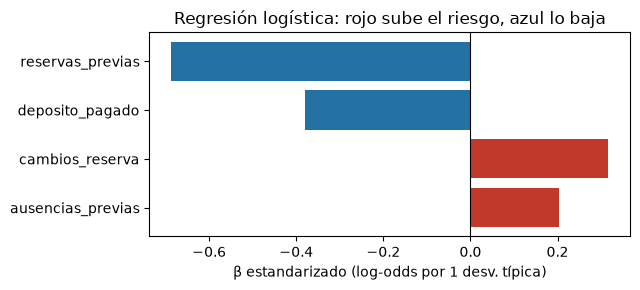

In [14]:
modelo_lr.fit(X_train, y_train)
scaler = modelo_lr.named_steps["scaler"]
clf = modelo_lr.named_steps["clf"]
beta = pd.Series(clf.coef_[0], index=VARIABLES_FFS)

coeficientes = pd.DataFrame({
    "β (por 1 desv. típica)": beta,
    "odds ratio (por 1 desv.)": np.exp(beta),
    "desv. típica de la variable": scaler.scale_,
    "β (por unidad)": beta / scaler.scale_,
    "odds ratio (por unidad)": np.exp(beta / scaler.scale_),
}).sort_values("β (por 1 desv. típica)", key=abs, ascending=False)
print(f"Intercepto (log-odds con todas las variables en su media): {clf.intercept_[0]:.3f}")
display(coeficientes.round(3))

fig, ax = plt.subplots(figsize=(6.5, 3))
orden = coeficientes.index[::-1]
ax.barh(orden, coeficientes.loc[orden, "β (por 1 desv. típica)"],
        color=["#c0392b" if b > 0 else "#2471a3" for b in coeficientes.loc[orden, "β (por 1 desv. típica)"]])
ax.axvline(0, color="k", lw=0.8)
ax.set(xlabel="β estandarizado (log-odds por 1 desv. típica)",
       title="Regresión logística: rojo sube el riesgo, azul lo baja")
plt.tight_layout()
fig.savefig("figuras/lr_coeficientes.png", dpi=200, bbox_inches="tight")
plt.show()

Los betas estandarizados nos indican el efecto de subir cada variable una desviación típica. En este caso vemos que reservas_previas es la más importante, pero con una relación negativa, es decir, cuantas más reservas previas tuviese menos probable es que no se presente. Va seguido de deposito pagado, cambios reserva y ausencias previas. 

**Significación de los coeficientes.** scikit-learn no da errores estándar. Ajustamos la misma regresión logística con statsmodels sobre el entrenamiento original, sin sobremuestreo y sin regularización, para tener p-valores e intervalos de confianza. El sobremuestreo aleatorio equivale a dar más peso a la clase positiva, y en una regresión logística eso mueve sobre todo el intercepto, no las pendientes, por eso los coeficientes por unidad deben salir parecidos en los dos ajustes.

In [15]:
logit_sm = sm.Logit(y_train, sm.add_constant(X_train[VARIABLES_FFS])).fit(disp=0)
ic = logit_sm.conf_int()
significacion = pd.DataFrame({
    "β statsmodels (por unidad)": logit_sm.params,
    "IC 95 % inf.": ic[0],
    "IC 95 % sup.": ic[1],
    "p-valor": logit_sm.pvalues,
    "β scikit-learn + sobremuestreo (por unidad)": pd.concat([
        pd.Series({"const": clf.intercept_[0] - (beta / scaler.scale_ * scaler.mean_).sum()}),
        beta / scaler.scale_]),
})
display(significacion.round(4))

,β statsmodels (por unidad),IC 95 % inf.,IC 95 % sup.,p-valor,β scikit-learn + sobremuestreo (por unidad)
const,-1.7121,-1.9457,-1.4785,0.0,0.7887
deposito_pagado,-0.7518,-0.9799,-0.5236,0.0,-0.7842
reservas_previas,-0.3468,-0.4264,-0.2671,0.0,-0.3494
cambios_reserva,0.3992,0.2941,0.5043,0.0,0.3691
ausencias_previas,0.9966,0.6449,1.3483,0.0,0.8695


**Lectura de los coeficientes** (por unidad de la variable original, con el ajuste de scikit-learn):

- deposito_pagado (odds ratio 0,46): pagar depósito multiplica las odds de no presentarse por 0,46, es decir, las reduce algo más de la mitad. Es la protección más fuerte por unidad.
- reservas_previas (0,71): cada reserva anterior en el hotel reduce las odds un 30 %. Es la variable con mayor efecto estandarizado (β = −0,69 por desviación típica, unas dos reservas), porque varía mucho entre clientes.
- cambios_reserva (1,45): cada cambio en la reserva multiplica las odds por 1,45 (+45 %).
- ausencias_previas (2,39): un cliente que ya faltó alguna vez tiene 2,4 veces más odds de no presentarse. Por unidad es el efecto más grande, pero su coeficiente estandarizado es el menor porque solo un 6 % de las reservas tiene un 1 (desviación típica 0,24): afecta mucho, pero a pocas reservas.

Los signos tienen sentido para el negocio, la fidelidad y el depósito protegen mientras que los cambios y el historial de ausencias son señales de riesgo.

**Significación.** Los cuatro coeficientes tienen p-valor < 0,001 y ningún intervalo de confianza al 95 % contiene el 0. Las pendientes con sobremuestreo son casi iguales a las de statsmodels sin sobremuestreo. Las pequeñas diferencias probablemente vienen de la regularización L2 que scikit-learn aplica por defecto. 

Lo que cambia es el intercepto: −1,71 sin sobremuestreo frente a +0,79 con él. La diferencia (2,50) es prácticamente $\log(4140/360) = \log(11{,}5) = 2{,}44$, el logaritmo del factor por el que el sobremuestreo multiplica los positivos. Confirma que el sobremuestreo desplaza las probabilidades hacia arriba sin cambiar lo que el modelo dice de cada variable.

### 2.2 Explicación local: por qué el modelo puntúa así una reserva

Para una reserva concreta, cada variable aporta $\beta_j z_j$ al log-odds, donde $z_j$ es su valor estandarizado (cuántas desviaciones típicas está por encima o por debajo de la media del entrenamiento). El intercepto es el punto de partida, la reserva "media", y la suma de las aportaciones da la predicción. Elegimos tres reservas de test con el umbral de trabajo (elegido en validación):

- **A**, el no presentado detectado con mayor probabilidad (verdadero positivo),
- **B**, el no presentado peor puntuado (falso negativo, el error caro),
- **C**, el cliente que sí vino y recibió la probabilidad más alta (falso positivo).

Usaremos las mismas tres reservas para comparar con SHAP en el apartado 4.

In [16]:
prob_cv_lr = cross_val_predict(modelo_lr, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
UMBRAL_LR, tabla_umbral_lr = elegir_umbral(prob_cv_lr)
print("Umbrales en VALIDACIÓN (regresión logística FFS):")
display(tabla_umbral_lr.round(3))
print(f"Umbral de trabajo: {UMBRAL_LR}")

prob_test_lr = modelo_lr.predict_proba(X_test)[:, 1]
pred_test_lr = (prob_test_lr >= UMBRAL_LR).astype(int)
p = pd.Series(prob_test_lr, index=X_test.index)
CASOS = {
    "A · verdadero positivo": p[(y_test == 1) & (pred_test_lr == 1)].idxmax(),
    "B · falso negativo":     p[(y_test == 1) & (pred_test_lr == 0)].idxmin(),
    "C · falso positivo":     p[(y_test == 0) & (pred_test_lr == 1)].idxmax(),
}
casos = d.loc[list(CASOS.values())].assign(caso=list(CASOS.keys()),
                                            prob_LR=[p[i] for i in CASOS.values()]).set_index("caso")
display(casos.round(3))

Umbrales en VALIDACIÓN (regresión logística FFS):


,precision,recall,F1,TP,FP,FN,TN,coste por 1.000 reservas (€)
umbral,,,,,,,,
0.3,0.105,0.931,0.189,335,2859,25,1281,2294.889
0.5,0.158,0.681,0.257,245,1305,115,2835,2658.889
0.7,0.248,0.306,0.274,110,334,250,3806,4111.556


Umbral de trabajo: 0.3


,id_reserva,antelacion_dias,noches,huespedes,precio_noche_eur,reservas_previas,ausencias_previas,cambios_reserva,solicitudes_especiales,deposito_pagado,llegada_fin_semana,no_presentado,prob_LR
caso,,,,,,,,,,,,,
A · verdadero positivo,R03963,20,1,2,132.45,1,1,3,1,0,0,1,0.918
B · falso negativo,R04060,93,4,2,123.33,4,0,0,1,1,1,1,0.199
C · falso positivo,R03165,8,2,2,127.60,1,1,4,1,0,0,0,0.942


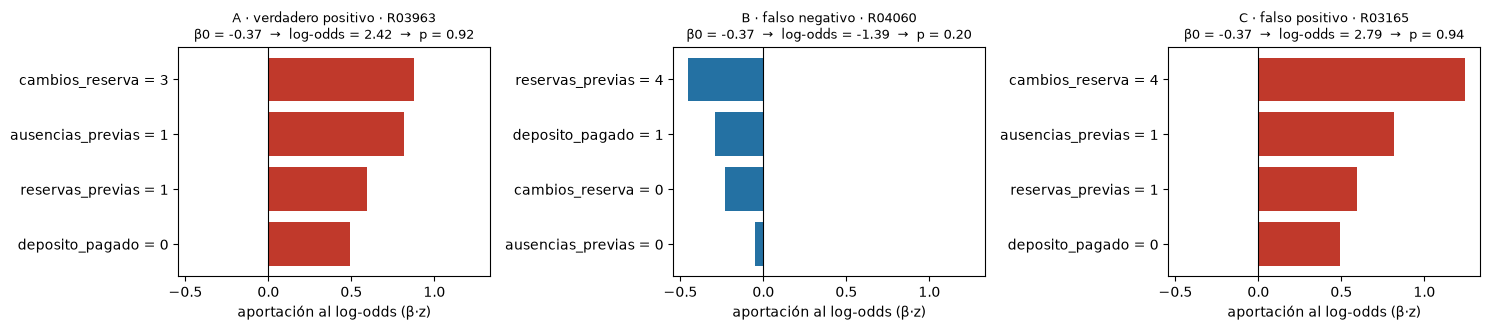

In [17]:
def contribuciones_lr(i):
    z = scaler.transform(X_test.loc[[i], VARIABLES_FFS])[0]
    return pd.Series(beta.values * z, index=VARIABLES_FFS)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.4), sharex=True)
for ax, (nombre, i) in zip(axes, CASOS.items()):
    contrib = contribuciones_lr(i)
    logit = clf.intercept_[0] + contrib.sum()
    prob = 1 / (1 + np.exp(-logit))
    assert np.isclose(prob, p[i]), "La suma de contribuciones no reproduce la probabilidad"
    contrib = contrib.reindex(contrib.abs().sort_values().index)
    etiquetas = [f"{c} = {X_test.loc[i, c]:g}" for c in contrib.index]
    ax.barh(etiquetas, contrib, color=["#c0392b" if v > 0 else "#2471a3" for v in contrib])
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(f"{nombre} · {d.loc[i, 'id_reserva']}\n"
                 f"β0 = {clf.intercept_[0]:.2f}  →  log-odds = {logit:.2f}  →  p = {prob:.2f}", fontsize=9)
    ax.set_xlabel("aportación al log-odds (β·z)")
plt.tight_layout()
fig.savefig("figuras/lr_explicaciones_locales.png", dpi=200, bbox_inches="tight")
plt.show()

En validación, el umbral de menor coste vuelve a ser 0,3 (2.295 € por cada 1.000 reservas frente a 2.659 € con 0,5), igual que en la primera práctica.

- **A · verdadero positivo** (R03963, p = 0,92). En este caso Las cuatro variables empujan hacia arriba: sin depósito, solo una reserva previa y con una ausencia, y tres cambios. Pesan más cambios_reserva (+0,88) y ausencias_previas (+0,82). El hecho de que ya cambiase reservas anteriores 3 veces y ya tenga una ausencia anterior implican que el hotel tendría un motivo concreto para llamar.
- **B · falso negativo** (R04060, p = 0,20, por debajo de 0,3). En este caso todas las 4 variables empujaban a que este cliente sí se presentaría aunque luego ocurrió lo contrario. Es un cliente fiel (4 reservas previas sin ausencias), con depósito y sin cambios: las cuatro variables bajan el riesgo, sobre todo reservas_previas (−0,46). El modelo no tiene ninguna señal de alarma, con estas variables este no presentado no se podía anticipar.
- **C · falso positivo** (R03165, p = 0,94). Tiene casi el mismo perfil que A (sin depósito, una reserva previa con ausencia, cuatro cambios) y recibe incluso más probabilidad, pero sí se presentó. Con estas cuatro variables A y C son prácticamente indistinguibles: el error no es un fallo puntual del modelo, sino que falta información para separarlos.

Las probabilidades están infladas por el sobremuestreo (el intercepto parte de una reserva media con p ≈ 0,41, no del 8 % real), así que sirven para ordenar reservas por riesgo y para explicar qué empuja hacia arriba o hacia abajo, no como probabilidades reales.

**Relación con SHAP.** Para un modelo lineal con variables independientes, el valor SHAP de cada variable es exactamente $\beta_j (x_j - \bar{x}_j)$, que es lo que acabamos de calcular (en $z$ la media del entrenamiento ya es 0). Lo comprobamos con el `LinearExplainer` de la librería `shap`, usando el entrenamiento escalado como datos de fondo:

In [18]:
Z_train = scaler.transform(X_train[VARIABLES_FFS])
Z_casos = scaler.transform(X_test.loc[list(CASOS.values()), VARIABLES_FFS])
fondo = shap.maskers.Independent(Z_train, max_samples=len(Z_train))   # todo el entrenamiento como fondo
shap_lineal = shap.LinearExplainer(clf, fondo).shap_values(Z_casos)
manual = np.vstack([contribuciones_lr(i).values for i in CASOS.values()])
print("Máxima diferencia entre β·z y los valores SHAP del LinearExplainer:", np.abs(shap_lineal - manual).max().round(6))

Máxima diferencia entre β·z y los valores SHAP del LinearExplainer: 0.0


Esto sirve como demostración de que la regresión logística es interpretable y explicable por sí misma.

### 2.3 Evaluación en test

El modelo se ajustó con todo el entrenamiento y se evalúa una sola vez en test, con el umbral fijado en validación. Lo comparamos con el modelo de la primera práctica (las 10 variables), evaluado igual.

In [19]:
modelo_p1 = regresion_logistica_ros()
prob_cv_p1 = cross_val_predict(modelo_p1, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
UMBRAL_P1, _ = elegir_umbral(prob_cv_p1)
prob_test_p1 = modelo_p1.fit(X_train, y_train).predict_proba(X_test)[:, 1]

test_resumen = pd.DataFrame([
    {"modelo": "LR 10 variables (práctica 1)", **metricas_test(prob_test_p1, UMBRAL_P1)},
    {"modelo": f"LR {len(VARIABLES_FFS)} variables FFS", **metricas_test(prob_test_lr, UMBRAL_LR)},
]).set_index("modelo")
print("TEST · cada modelo con su umbral elegido en validación")
display(test_resumen.round(3))

TEST · cada modelo con su umbral elegido en validación


,umbral,precision,recall,F1,TP,FP,FN,TN,coste por 1.000 reservas (€),ROC-AUC,AP
modelo,,,,,,,,,,,
LR 10 variables (práctica 1),0.3,0.109,0.908,0.194,109,893,11,487,2299.333,0.749,0.215
LR 4 variables FFS,0.3,0.105,0.900,0.189,108,916,12,464,2392.000,0.736,0.198


En test, con el umbral 0,3 fijado en validación, el modelo de 4 variables detecta 108 de los 120 no presentados (recall 0,90), uno menos que el de 10 variables, y hace 23 llamadas innecesarias más (916 frente a 893). Su coste es algo mayor (2.392 € frente a 2.299 € por cada 1.000 reservas) y también su ROC-AUC y AP son algo menores (0,736 frente a 0,749 y 0,198 frente a 0,215). 

Con 120 positivos en test estas diferencias son pequeñas, pero van en la misma dirección que la AP en validación, las variables descartadas, sobre todo la antelación, aportan algo de información que la F1 con umbral 0,5 no llegó a ver.

Es interesante que en validación cruzada el modelo reducido rendía prácticamente igual que el completo (incluso con una F1 algo mayor), mientras que en test queda ligeramente por debajo en todas las métricas. Esto refleja la variabilidad de los resultados según el conjunto de datos sobre el que se evalúa, el test solo contiene 120 no presentados, así que detectar uno más o uno menos (aquí la diferencia es de un solo verdadero positivo) mueve las métricas de forma apreciable. En ambos casos las diferencias son pequeñas, por lo que el hotel no asumiría una pérdida de rendimiento importante al simplificar el modelo. A cambio, obtiene un modelo que se explica con cuatro variables y necesita recoger menos información de cada reserva.

Es el precio de un modelo que se explica con cuatro variables; en el apartado 3.5 volvemos sobre ello.

## 3. Un modelo no interpretable con SHAP

Para el modelo no interpretable se elige entrenar un random forest. Cientos de árboles con interacciones y cortes no lineales, cuya predicción no se puede leer directamente. Lo elegimos frente a otras cajas negras (gradient boosting, redes neuronales) porque SHAP tiene para los modelos de árboles un explicador exacto y rápido (Tree SHAP, TreeExplainer), porque permite comparar SHAP con la importancia por defecto del bosque (feature_importances_), y porque no necesita escalado, así que las explicaciones quedan en las unidades originales. 

Le damos las 10 variables, no solo las del FFS, por dos razones, un modelo no lineal podría aprovechar variables que no le servían a la regresión (por ejemplo, si el efecto de la antelación no es lineal), y así SHAP nos sirve también para contrastar la selección del apartado 1.

El desequilibrio se trata igual que antes (sobremuestreo dentro del Pipeline). Los árboles no necesitan escalado. Se elige previamente la profundidad y el tamaño mínimo de hoja con GridSearchCV sobre el mismo cv y la misma F1.

In [20]:
rf_pipeline = ImbPipeline([
    ("sampler", RandomOverSampler(random_state=SEED)),
    ("clf", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
])
busqueda = GridSearchCV(
    rf_pipeline,
    param_grid={"clf__max_depth": [4, 6, 8, None], "clf__min_samples_leaf": [5, 20, 50]},
    scoring=scoring["f1"], cv=cv, n_jobs=-1,
)
busqueda.fit(X_train, y_train)
rejilla = pd.DataFrame(busqueda.cv_results_).pivot_table(
    index="param_clf__max_depth", columns="param_clf__min_samples_leaf", values="mean_test_score", dropna=False)
print("F1 media en validación cruzada por combinación (filas: max_depth, columnas: min_samples_leaf):")
display(rejilla.round(3))
print("Mejores hiperparámetros:", busqueda.best_params_)

modelo_rf = busqueda.best_estimator_
evaluar_cv("Random forest + sobremuestreo · 10 variables", modelo_rf)
tabla_resultados()

F1 media en validación cruzada por combinación (filas: max_depth, columnas: min_samples_leaf):


param_clf__min_samples_leaf,5,20,50
param_clf__max_depth,,,
4.0,0.251,0.253,0.251
6.0,0.247,0.248,0.244
8.0,0.233,0.250,0.244
NaN,0.217,0.253,0.237


Mejores hiperparámetros: {'clf__max_depth': 4, 'clf__min_samples_leaf': 20}


,f1,precision,recall,roc_auc,AP
LR + sobremuestreo · 10 variables (práctica 1),0.254 ± 0.016,0.157 ± 0.011,0.672 ± 0.052,0.740 ± 0.018,0.245 ± 0.044
FFS dentro del Pipeline (CV anidada),0.252 ± 0.010,0.155 ± 0.007,0.664 ± 0.034,0.746 ± 0.014,0.238 ± 0.035
LR + sobremuestreo · 4 variables FFS,0.257 ± 0.015,0.158 ± 0.010,0.681 ± 0.063,0.742 ± 0.015,0.230 ± 0.035
Random forest + sobremuestreo · 10 variables,0.253 ± 0.011,0.155 ± 0.008,0.683 ± 0.039,0.739 ± 0.019,0.226 ± 0.036


In [21]:
prob_cv_rf = cross_val_predict(modelo_rf, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
UMBRAL_RF, tabla_umbral_rf = elegir_umbral(prob_cv_rf)
print("Umbrales en VALIDACIÓN (random forest):")
display(tabla_umbral_rf.round(3))
print(f"Umbral de trabajo: {UMBRAL_RF}")

prob_test_rf = modelo_rf.predict_proba(X_test)[:, 1]   # best_estimator_ ya está ajustado con todo el entrenamiento
test_resumen.loc["Random forest 10 variables"] = metricas_test(prob_test_rf, UMBRAL_RF)
print("TEST · cada modelo con su umbral elegido en validación")
display(test_resumen.round(3))

Umbrales en VALIDACIÓN (random forest):


,precision,recall,F1,TP,FP,FN,TN,coste por 1.000 reservas (€)
umbral,,,,,,,,
0.3,0.101,0.928,0.182,334,2971,26,1169,2385.111
0.5,0.155,0.683,0.253,246,1342,114,2798,2668.000
0.7,0.313,0.172,0.222,62,136,298,4004,4726.222


Umbral de trabajo: 0.3
TEST · cada modelo con su umbral elegido en validación


,umbral,precision,recall,F1,TP,FP,FN,TN,coste por 1.000 reservas (€),ROC-AUC,AP
modelo,,,,,,,,,,,
LR 10 variables (práctica 1),0.3,0.109,0.908,0.194,109,893,11,487,2299.333,0.749,0.215
LR 4 variables FFS,0.3,0.105,0.900,0.189,108,916,12,464,2392.000,0.736,0.198
Random forest 10 variables,0.3,0.103,0.942,0.185,113,988,7,392,2302.667,0.740,0.226


La rejilla elige árboles poco profundos (max_depth=4, min_samples_leaf=20). Los árboles sin límite y con hojas pequeñas empeoran claramente (F1 0,213): con el sobremuestreo, cada no presentado aparece unas once veces en el entrenamiento y un árbol profundo memoriza esas copias.

En validación cruzada el random forest no mejora a la regresión logística. En test, con su umbral de 0,3, detecta más no presentados (113 de 120, recall 0,94) a cambio de más llamadas innecesarias (988), con un coste casi igual al del modelo de la primera práctica (2.303 € frente a 2.299 €) y la mejor AP de los tres (0,226).

Que un modelo mucho más flexible no gane indica que la relación entre las variables y la clase es casi aditiva y monótona, que es justo lo que una regresión logística capta bien.

### 3.1 Valores SHAP

SHAP reparte cada predicción entre las variables. Por la propiedad de **eficiencia**, para cada reserva se cumple

$$f(x) = \underbrace{E[f(X)]}_{\text{valor base}} + \sum_j \phi_j(x),$$

es decir, las contribuciones suman la diferencia entre su predicción y la predicción media. Usamos TreeExplainer, que calcula los valores exactos para modelos de árboles de forma eficiente (Tree SHAP). Explicamos la probabilidad de no presentarse (clase 1) en las 1.500 reservas de test.

El valor base es la predicción media del bosque sobre los datos con los que se entrenó, que están sobremuestreados al 50 %. Por eso ronda 0,5 y no el 8 % real: SHAP explica el modelo tal como es, y este modelo da probabilidades infladas por el remuestreo (igual que la regresión logística).

In [22]:
rf = modelo_rf.named_steps["clf"]
explainer = shap.TreeExplainer(rf)
explicacion = explainer(X_test)
sv = explicacion[:, :, 1]   # valores SHAP de la clase positiva (no_presentado = 1)

valor_base = float(np.atleast_1d(sv.base_values)[0])
reconstruida = sv.base_values + sv.values.sum(axis=1)
print(f"Valor base E[f(X)]: {valor_base:.3f}")
print("Eficiencia: máxima diferencia entre valor base + Σ SHAP y predict_proba =",
      f"{np.abs(reconstruida - prob_test_rf).max():.2e}")

Valor base E[f(X)]: 0.500
Eficiencia: máxima diferencia entre valor base + Σ SHAP y predict_proba = 2.11e-15


La máxima diferencia es prácticamente 0, por tanto damos por bueno que se cumple la propiedad de eficiencia.

### 3.2 Explicación global

**Importancia (media de |SHAP|).** Cuánto mueve de media cada variable la probabilidad predicha, en puntos de probabilidad.

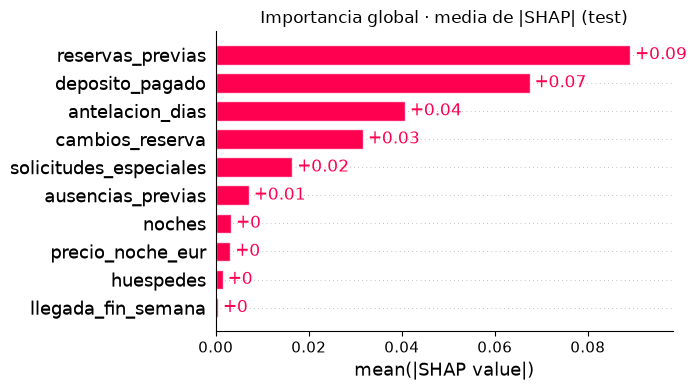

In [23]:
plt.figure()
shap.plots.bar(sv, max_display=10, show=False)
plt.title("Importancia global · media de |SHAP| (test)")
plt.gcf().set_size_inches(7, 4)
plt.tight_layout()
plt.savefig("figuras/shap_importancia.png", dpi=200, bbox_inches="tight")
plt.show()

**Summary plot.** Cada punto es una reserva de test. La posición horizontal es su valor SHAP (a la derecha sube la probabilidad de no presentarse) y el color es el valor de la variable (rojo alto, azul bajo). Añade a la importancia la dirección del efecto.

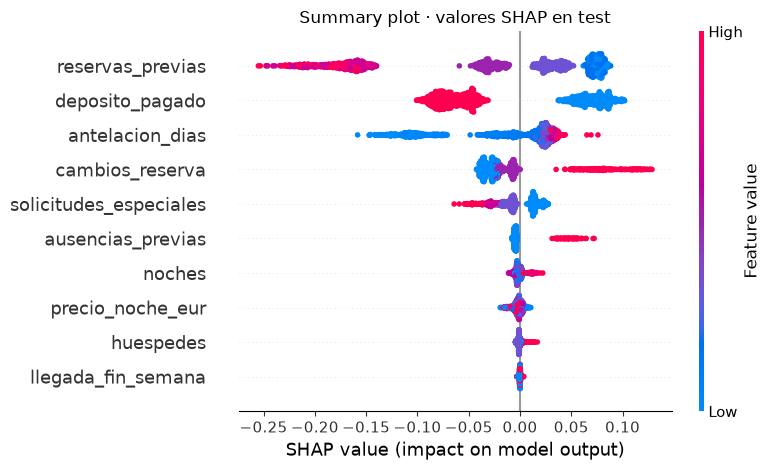

In [24]:
plt.figure()
shap.plots.beeswarm(sv, max_display=10, show=False)
plt.title("Summary plot · valores SHAP en test")
plt.gcf().set_size_inches(8, 4.8)
plt.tight_layout()
plt.savefig("figuras/shap_beeswarm.png", dpi=200, bbox_inches="tight")
plt.show()

Las variables reservas_previas (0,089) y deposito_pagado (0,068) son con diferencia las que más mueven la predicción (de media), seguidas de antelacion_dias (0,041), cambios_reserva (0,032) y solicitudes_especiales (0,017). ausencias_previas queda sexta (0,007). noches, precio_noche_eur, huespedes y llegada_fin_semana apenas se usan (≤ 0,003).

En el summary plot podemos ver cada caso individual. Vemos que en el caso de ausencias los casos donde afecta mucho si que tienen un impacto positivo en la probabilidad del modelo, no obstante estos casos son poco frecuentes de ahi su bajo valor medio. 
En las dos primeras variables vemos una gran concentración de casos en los que tienen un valor muy alto y que tienen un impacto alto negativo y cuando tienen un valor bajo impactan en el sentido contrario, también con una frecuencia considerable. Es decir, la relación inversa de estas variables sobre la clase es confirmada así como su fuerza.

Para las últimas cuatro variables se observa que todos sus casos sin importar su valor no aportan prácticamente nada, luego sus valores bajos en la media SHAP no son consecuencia de la ponderación.

**Dirección conclusiones**
- Pocas reservas previas (azul) suben el riesgo y muchas (rojo) lo bajan con fuerza (hasta −0,25).
- Haber pagado depósito lo baja.
- Muchos cambios lo suben.
- Más solicitudes especiales lo bajan.
- Tener una ausencia previa lo sube.

Todo coincide en signo con la regresión logística. Lo que difiere y llama la atención es antelacion_dias: las antelaciones bajas (azul) tienen valores SHAP muy negativos, es decir, las reservas hechas con pocos días de margen casi siempre se presentan, mientras que las antelaciones medias y altas suben un poco el riesgo. Es una variable que el FFS dejó fuera.

**Dependence plots.** Valor SHAP de una variable frente a su valor, reserva a reserva. Muestran la forma del efecto (lineal, con escalón, con saturación, etc.) y, con el color, la variable con la que más interactúa según shap. Se hacen para las cuatro variables más importantes.

Media de |SHAP| (puntos de probabilidad):


,reservas_previas,deposito_pagado,antelacion_dias,cambios_reserva,solicitudes_especiales,ausencias_previas,noches,precio_noche_eur,huespedes,llegada_fin_semana
media |SHAP|,0.0891,0.0675,0.0407,0.0317,0.0165,0.0071,0.0033,0.0032,0.0015,0.0005


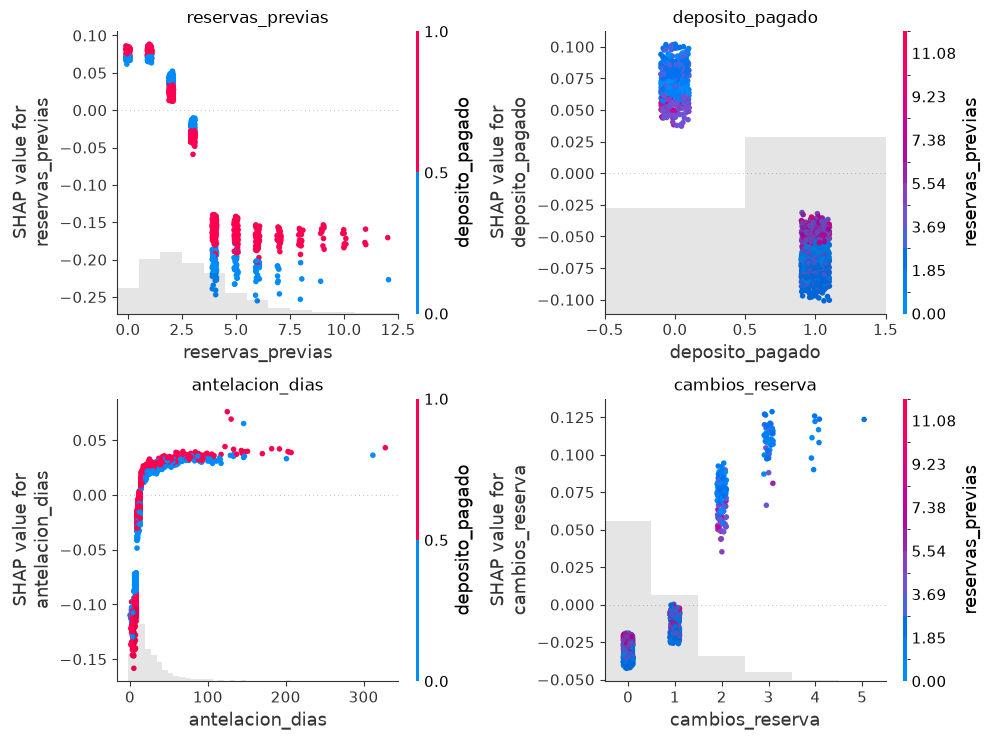

In [25]:
importancia_shap = pd.Series(np.abs(sv.values).mean(axis=0), index=X.columns).sort_values(ascending=False)
print("Media de |SHAP| (puntos de probabilidad):")
display(importancia_shap.round(4).to_frame("media |SHAP|").T)
variables_dep = list(importancia_shap.index[:4])

fig, axes = plt.subplots(2, 2, figsize=(10, 7.5))
for ax, c in zip(axes.ravel(), variables_dep):
    shap.plots.scatter(sv[:, c], color=sv, ax=ax, show=False)
    ax.set_title(c)
plt.tight_layout()
fig.savefig("figuras/shap_dependence.png", dpi=200, bbox_inches="tight")
plt.show()

- **antelacion_dias** tiene el efecto menos lineal de todos. Por debajo de unos 10 días el valor SHAP cae hasta −0,15 (riesgo mucho menor) y a partir de unos 20 días se queda plano en torno a +0,03, igual con 30 que con 300 días. Una regresión logística con los días en escala lineal no puede representar un efecto concentrado en los primeros días y plano en una cola larga y asimétrica. Por eso añadirla tal cual no mejoraba la F1 y el FFS la descartó.
- **reservas_previas** tiene forma de escalón, no de recta: 0 o 1 reservas previas suben el riesgo (+0,08), 2 lo suben algo menos, 3 lo bajan y a partir de 4 el efecto se estabiliza en torno a −0,15/−0,25. El color muestra una interacción con el depósito: con 4 o más reservas, los clientes sin depósito (azul) tienen un SHAP más negativo. Para un cliente sin depósito, que partiría de un riesgo alto, la fidelidad pesa más.
- **deposito_pagado** separa dos bloques: sin depósito +0,05 a +0,10 y con depósito −0,03 a −0,10. La dispersión vertical dentro de cada bloque es de nuevo la interacción con reservas_previas.
- **cambios_reserva** es creciente con saturación: 0 o 1 cambios bajan algo el riesgo, 2 cambios lo suben unos +0,07 y 3 o más alrededor de +0,11.

**Valores de interacción.** Tree SHAP también reparte la predicción entre pares de variables: la diagonal es el efecto propio de cada variable y fuera de la diagonal está la parte que solo aparece por la combinación de dos. Son caros de calcular, así que usamos 300 reservas de test.

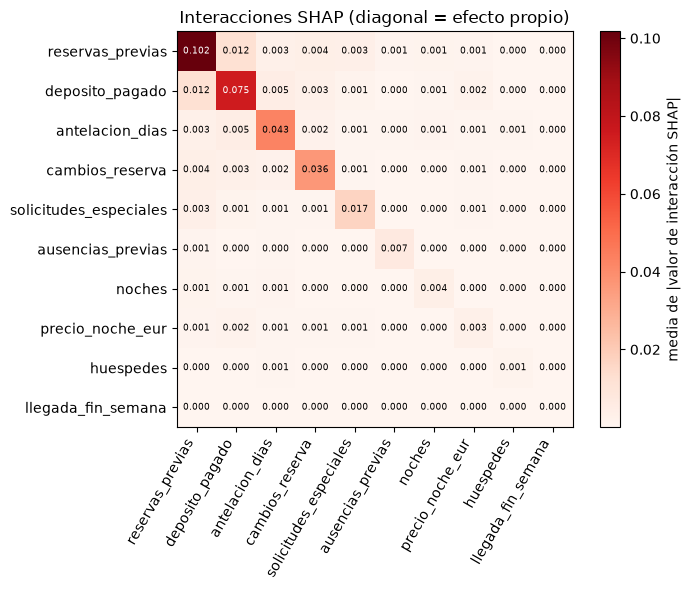

Pares con más interacción (suma de las dos mitades simétricas):


,,|interacción| media
deposito_pagado,reservas_previas,0.0242
antelacion_dias,deposito_pagado,0.0090
cambios_reserva,reservas_previas,0.0072
reservas_previas,solicitudes_especiales,0.0070
antelacion_dias,reservas_previas,0.0057


In [26]:
inter = np.asarray(explainer.shap_interaction_values(X_test.iloc[:300]))
if inter.ndim == 4:                      # (reservas, variables, variables, clases) -> clase positiva
    inter = inter[..., 1] if inter.shape[-1] == 2 else inter[1]
media_inter = pd.DataFrame(np.abs(inter).mean(axis=0), index=X.columns, columns=X.columns)
orden_v = importancia_shap.index
media_inter = media_inter.loc[orden_v, orden_v]

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(media_inter, cmap="Reds")
ax.set_xticks(range(len(orden_v)), orden_v, rotation=60, ha="right")
ax.set_yticks(range(len(orden_v)), orden_v)
for i in range(len(orden_v)):
    for j in range(len(orden_v)):
        ax.text(j, i, f"{media_inter.iat[i, j]:.3f}", ha="center", va="center", fontsize=6.5,
                color="white" if media_inter.iat[i, j] > media_inter.values.max() / 2 else "black")
fig.colorbar(im, ax=ax, label="media de |valor de interacción SHAP|")
ax.set_title("Interacciones SHAP (diagonal = efecto propio)")
plt.tight_layout()
fig.savefig("figuras/shap_interacciones.png", dpi=200, bbox_inches="tight")
plt.show()

fuera_diag = media_inter.where(~np.eye(len(orden_v), dtype=bool)).stack()
fuera_diag = fuera_diag[[a < b for a, b in fuera_diag.index]] * 2   # cada par aparece dos veces (i,j) y (j,i)
print("Pares con más interacción (suma de las dos mitades simétricas):")
display(fuera_diag.sort_values(ascending=False).head(5).round(4).to_frame("|interacción| media"))

La diagonal (efectos propios) domina claramente. La interacción más fuerte es la de reservas_previas con deposito_pagado (0,024 sumando los dos lados de la matriz), la que ya se veía en los *dependence plots*, y es pequeña frente a sus efectos propios (0,102 y 0,075). Los demás pares no llegan a 0,01. Esto significa que el bosque ha aprendido un modelo casi aditivo, cada variable aporta por su cuenta, con formas no lineales (escalones, saturación) pero apenas combinándose. Eso explica que una regresión logística, que también es aditiva, rinda igual.

### 3.3 Explicación local

Las mismas tres reservas del apartado 2.2. El *waterfall plot* parte del valor base y va sumando la aportación de cada variable hasta llegar a la probabilidad que da el bosque a esa reserva.

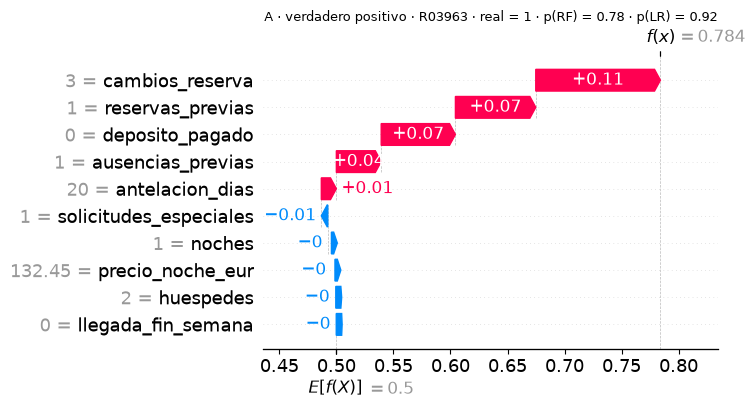

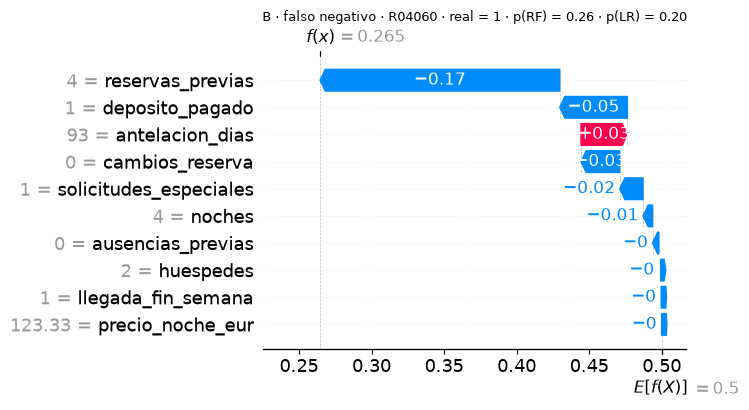

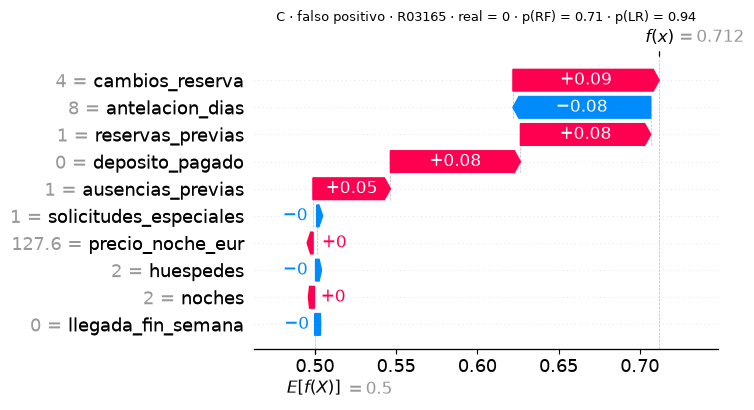

In [27]:
posiciones = {nombre: X_test.index.get_loc(i) for nombre, i in CASOS.items()}
for nombre, pos in posiciones.items():
    i = X_test.index[pos]
    plt.figure()
    shap.plots.waterfall(sv[pos], max_display=10, show=False)
    plt.title(f"{nombre} · {d.loc[i, 'id_reserva']} · real = {y_test.loc[i]} · "
              f"p(RF) = {prob_test_rf[pos]:.2f} · p(LR) = {prob_test_lr[pos]:.2f}", fontsize=9)
    plt.gcf().set_size_inches(7.5, 4.2)
    plt.tight_layout()
    plt.savefig(f"figuras/shap_waterfall_{nombre[0]}.png", dpi=200, bbox_inches="tight")
    plt.show()

El mismo caso A en formato *force plot*: las variables en rojo empujan la probabilidad hacia arriba desde el valor base y las azules hacia abajo.

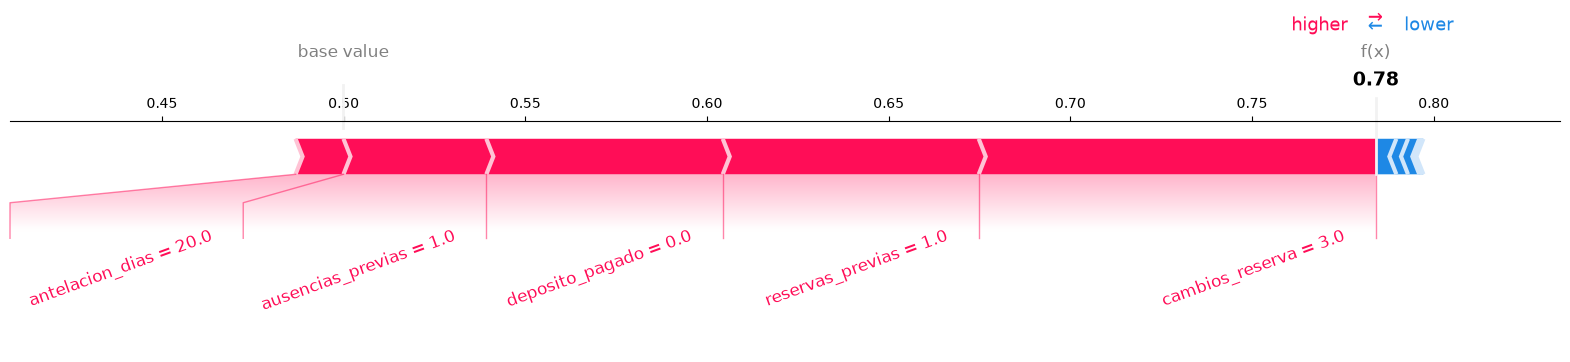

In [28]:
pos_A = posiciones["A · verdadero positivo"]
shap.plots.force(valor_base, sv.values[pos_A], X_test.iloc[pos_A].round(2), matplotlib=True, show=False,
                 text_rotation=20)
plt.savefig("figuras/shap_force_A.png", dpi=200, bbox_inches="tight")
plt.show()

In [29]:
# Las tres reservas: aportaciones de la regresión logística (log-odds) frente a SHAP del random forest (probabilidad)
comparacion_local = {}
for nombre, i in CASOS.items():
    pos = X_test.index.get_loc(i)
    comparacion_local[(nombre, "LR · β·z (log-odds)")] = contribuciones_lr(i).reindex(X.columns)
    comparacion_local[(nombre, "RF · SHAP (prob.)")] = pd.Series(sv.values[pos], index=X.columns)
comparacion_local = pd.DataFrame(comparacion_local).loc[importancia_shap.index]
display(comparacion_local.round(3))

A · verdadero positivo                    \
                          LR · β·z (log-odds) RF · SHAP (prob.)   
reservas_previas                        0.592             0.070   
deposito_pagado                         0.493             0.065   
antelacion_dias                           NaN             0.013   
cambios_reserva                         0.878             0.109   
solicitudes_especiales                    NaN            -0.006   
ausencias_previas                       0.819             0.039   
noches                                    NaN            -0.003   
precio_noche_eur                          NaN            -0.003   
huespedes                                 NaN            -0.001   
llegada_fin_semana                        NaN            -0.000   

                        B · falso negativo                    \
                       LR · β·z (log-odds) RF · SHAP (prob.)   
reservas_previas                    -0.457            -0.165   
deposito_pagado                     -0.291            -0.047   
antelacion_dias                        NaN             0.032   
cambios_reserva                     -0.229            -0.027   
solicitudes_especiales                 NaN            -0.016   
ausencias_previas                   -0.051            -0.004   
noches                                 NaN            -0.007   
precio_noche_eur                       NaN            -0.000   
huespedes                              NaN            -0.001   
llegada_fin_semana                     NaN            -0.000   

                        C · falso positivo                    
                       LR · β·z (log-odds) RF · SHAP (prob.)  
reservas_previas                     0.592             0.080  
deposito_pagado                      0.493             0.080  
antelacion_dias                        NaN            -0.085  
cambios_reserva                      1.247             0.090  
solicitudes_especiales                 NaN            -0.002  
ausencias_previas                    0.819             0.048  
noches                                 NaN             0.001  
precio_noche_eur                       NaN             0.002  
huespedes                              NaN            -0.002  
llegada_fin_semana                     NaN            -0.000

La regresión logística da sus aportaciones en log-odds y SHAP del bosque en probabilidad, así que se comparan signos y orden, no magnitudes.

- **A · verdadero positivo** (p = 0,78 en el bosque, 0,92 en la regresión). En este caso las importancias y efectos de las variables son practicamente iguales a las que obtuvimos con la regresión logística. Las cuatro variables principales son las mismas y todas afectan empujando hacia la clase positiva, lo que cambia es la ordenación de impacto. El resto apenas influyen que también concuerda con el descarte de FFS. 
- **B · falso negativo** (p = 0,26 en el bosque, 0,20 en la regresión; los dos por debajo de 0,3). En este caso llama la atención una variable que sí empuja hacia la clase positiva aunque en poca magnitud y que no estuvo considerada en la regresión (descartada por FFS), esta es la antelacion de días. No obstante, en general la tendencia empujaba hacia la clase negativa, la fidelidad (reservas_previas = 4, −0,17) domina, ayudada por el depósito (−0,05). Los dos modelos fallan por el mismo motivo, el perfil es de bajo riesgo.
- **C · falso positivo** (p = 0,71 en el bosque, 0,94 en la regresión). De nuevo en este caso la antelacion de días vuelve a empujar hacia la que era la clase correcta, la que fue descartada en el otro modelo por tanto esto es algo que el modelo de random forest sí es capaz de ver.Las mismas cuatro variables que en A empujan hacia arriba. El bosque lo acerca en la dirección correcta (de 0,94 a 0,71), aunque sigue por encima del umbral y se le llamaría igual.

### 3.4 SHAP frente a otras medidas de importancia

Juntamos en una tabla el orden que da cada método. La importancia por defecto del random forest (feature_importances) mide la reducción media de impureza en los cortes. Esa medida y las basadas en contar cortes no son consistentes: pueden dar menos importancia a una variable aunque el modelo dependa más de ella, y además favorecen a las variables con muchos valores distintos, que ofrecen más puntos de corte. Tree SHAP sí es consistente.

,valores distintos,SHAP: media |SHAP| (RF),RF: reducción de impureza,Filtro: |correlación|,Filtro: información mutua,FFS: orden de entrada,¿la eligió el FFS?
reservas_previas,14,1,1,2,1,2,sí
deposito_pagado,2,2,2,3,3,1,sí
antelacion_dias,152,3,3,5,4,9,no
cambios_reserva,8,4,4,1,2,3,sí
solicitudes_especiales,7,5,5,6,5,6,no
ausencias_previas,2,6,7,4,6,4,sí
noches,10,7,8,7,7,10,no
precio_noche_eur,3746,8,6,8,10,8,no
huespedes,4,9,9,9,8,5,no
llegada_fin_semana,2,10,10,10,9,7,no


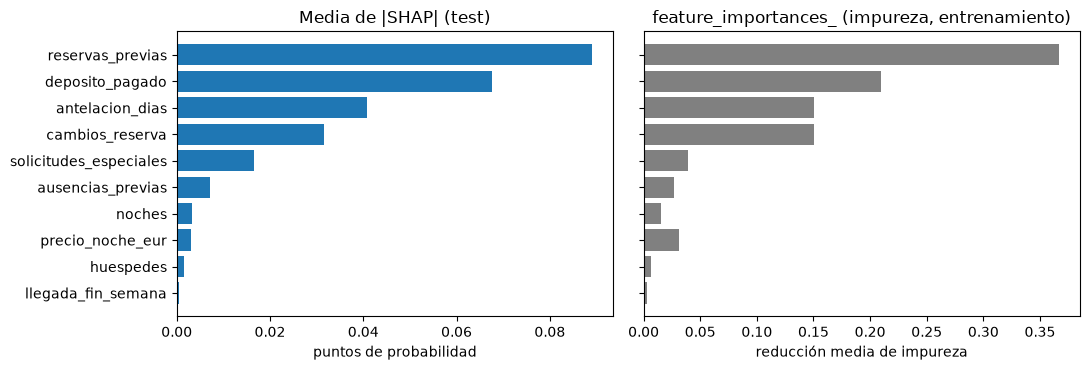

In [30]:
importancia_impureza = pd.Series(rf.feature_importances_, index=X.columns)
ranking = pd.DataFrame({
    "SHAP: media |SHAP| (RF)": importancia_shap.rank(ascending=False),
    "RF: reducción de impureza": importancia_impureza.rank(ascending=False),
    "Filtro: |correlación|": filtro["|correlación|"].rank(ascending=False),
    "Filtro: información mutua": filtro["información mutua"].rank(ascending=False),
    "FFS: orden de entrada": pd.Series({c: k for k, c in camino["variable añadida"].items()}),
}).astype(int)
ranking.insert(0, "valores distintos", X_train.nunique())
ranking["¿la eligió el FFS?"] = ["sí" if c in VARIABLES_FFS else "no" for c in ranking.index]
display(ranking.sort_values("SHAP: media |SHAP| (RF)"))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
orden_v = importancia_shap.index[::-1]
ax[0].barh(orden_v, importancia_shap[orden_v])
ax[0].set(title="Media de |SHAP| (test)", xlabel="puntos de probabilidad")
ax[1].barh(orden_v, importancia_impureza[orden_v], color="grey")
ax[1].set(title="feature_importances_ (impureza, entrenamiento)", xlabel="reducción media de impureza")
plt.tight_layout()
fig.savefig("figuras/shap_vs_impureza.png", dpi=200, bbox_inches="tight")
plt.show()

En este bosque las dos medidas ordenan casi igual las cinco primeras variables. La diferencia está donde la teoría la anticipa: precio_noche_eur, la variable con más valores distintos (3.746), sube al 6 puesto por impureza y queda 8 por SHAP, por delante de ausencias_previas (binaria), que es 6 por SHAP. Una variable continua ofrece muchos puntos de corte y gana reducciones de impureza en el entrenamiento que luego apenas cambian las predicciones. 

Aquí el efecto es moderado porque los árboles son poco profundos. Con árboles más profundos el sesgo suele ser mayor. Además, la impureza se calcula con el entrenamiento sobremuestreado y SHAP con el test. Por eso, para explicar el modelo, preferimos la media de |SHAP|.

**Todos los métodos frente a la selección.** Todos coinciden en el núcleo (reservas_previas, deposito_pagado y cambios_reserva siempre entre las cuatro primeras) y en que precio_noche_eur, huespedes, noches y llegada_fin_semana apenas aportan. Los desacuerdos tienen explicación:
- antelacion_dias es 9 en el FFS y 3 por SHAP porque su efecto no es lineal, y el FFS la evaluaba dentro de una regresión logística.
- ausencias_previas es 4 en el FFS y 6 por SHAP porque afecta a pocas reservas: entra en el modelo lineal por su efecto grande, pero pesa poco en la media.
- El filtro de información mutua, que capta dependencias no lineales, ya colocaba la antelación 4.

## 4. Conclusiones

**Selección de variables.** La selección hacia delante (wrapper) se queda con 4 de las 10 variables: deposito_pagado, reservas_previas, cambios_reserva y ausencias_previas. Con ellas la regresión logística rinde igual que con todas en validación cruzada. Las cuatro se eligen en las cinco particiones externas y coinciden con las cuatro primeras del filtro de correlación. Con el modelo no interpretable en el que mantuvimos las 10 variables vimos que FFS descartaba algunas que luego tendían a tener una importancia considerable en el random forest.

**Modelo interpretable.** La regresión logística se explica directamente. La fidelidad (reserva previa) y el depósito protegen; cada cambio (+45 %) y una ausencia previa (×2,4) son señales de riesgo. Los cuatro efectos son significativos y no dependen del sobremuestreo, que solo desplaza el intercepto. Los errores tienen sentido, el falso negativo es un cliente con perfil de bajo riesgo y el falso positivo es casi idéntico a un no presentado real. En test, con el umbral 0,3, detecta el 90 % de los no presentados, con una pérdida pequeña frente a las 10 variables.

**Modelo no interpretable con SHAP.** Un random forest no mejora a la regresión logística. SHAP explica por qué, el bosque usa las mismas variables principales, con los mismos signos y con interacciones débiles, es decir, aprendió un modelo casi aditivo. Lo que aporta de más es la forma no lineal de antelacion_dias (las reservas hechas con menos de unos 10 días casi siempre se presentan). La importancia por impureza coincide en lo esencial, pero sobrevalora precio_noche_eur, que es lo que se espera de una medida no consistente.

**Recomendación para el hotel.** Usar la regresión logística: con las variables del FFS, o con la antelación en escala logarítmica, que en validación iguala o supera al random forest. Rinde lo mismo y cada llamada se justifica con dos o tres razones que el personal entiende ("sin depósito, primera vez que viene, ha cambiado la reserva tres veces"). SHAP queda como herramienta de auditoría del modelo complejo y como guía para mejorar el sencillo.

**Limitaciones.**
- Las probabilidades de todos los modelos están infladas por el sobremuestreo (valor base 0,5 en lugar de 0,08). Sirven para ordenar reservas y explicarlas, no como probabilidades reales; para eso habría que calibrarlas.
- SHAP explica lo que hace el modelo, no relaciones causales: que el depósito baje la predicción no prueba que exigirlo reduzca las ausencias.
- El tamaño del dataset y el desequilibrio de la clase positiva. Con 120 no presentados en test, las diferencias de pocas centésimas entre modelos no son concluyentes.